In [21]:
from datasets import load_dataset

ds = load_dataset("cornell-movie-review-data/rotten_tomatoes")
ds

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 8530
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 1066
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 1066
    })
})

# Część 1: Przygotowanie tekstu, słownik i pary Skip-gram

### 1.1 Tokenizacja, normalizacja i budowa słownika

In [22]:
import re
import unicodedata
from collections import Counter

UNK_TOKEN = "<UNK>"
TOKEN_PATTERN = re.compile(r"[^\W_]+(?:'[^\W_]+)*")


def normalize_text(text):
    return unicodedata.normalize("NFKC", text).casefold()


def tokenize(text):
    return TOKEN_PATTERN.findall(normalize_text(text))


def build_vocabulary(training_texts):
    tokens = {token for text in training_texts for token in tokenize(text)}
    vocabulary = {UNK_TOKEN: 0}
    vocabulary.update({token: index for index, token in enumerate(sorted(tokens), start=1)})
    return vocabulary

In [23]:
train_texts = ds["train"]["text"]
vocabulary = build_vocabulary(train_texts)
id_to_token = {idx: token for token, idx in vocabulary.items()}
word_counts = Counter(token for text in train_texts for token in tokenize(text))

print(f"Liczba tekstow treningowych: {len(train_texts)}")
print(f"Rozmiar slownika: {len(vocabulary)}")
print("Przykladowe elementy slownika:", list(vocabulary.items())[:10])

Liczba tekstow treningowych: 8530
Rozmiar slownika: 17104
Przykladowe elementy slownika: [('<UNK>', 0), ('00', 1), ('007', 2), ('1', 3), ('10', 4), ('100', 5), ('101', 6), ('102', 7), ('104', 8), ('105', 9)]


### 1.2 Generowanie par Skip-gram (promień okna 2)

In [24]:
def extract_skipgram_pairs(tokens, window_size=2):
    pairs = []
    n = len(tokens)
    for i in range(n):
        center_token = tokens[i]
        start = max(0, i - window_size)
        end = min(n, i + window_size + 1)
        for j in range(start, end):
            if i != j:
                pairs.append((center_token, tokens[j]))
    return pairs


def generate_dataset_pairs(texts, vocabulary, window_size=2):
    token_pairs = []
    id_pairs = []
    for text in texts:
        tokens = tokenize(text)
        for i in range(len(tokens)):
            center = tokens[i]
            center_id = vocabulary.get(center, vocabulary[UNK_TOKEN])
            start = max(0, i - window_size)
            end = min(len(tokens), i + window_size + 1)
            for j in range(start, end):
                if i != j:
                    ctx = tokens[j]
                    ctx_id = vocabulary.get(ctx, vocabulary[UNK_TOKEN])
                    token_pairs.append((center, ctx))
                    id_pairs.append((center_id, ctx_id))
    return token_pairs, id_pairs

In [25]:
sample_sentence = "the cat likes milk"
sample_tokens = tokenize(sample_sentence)
sample_pairs = extract_skipgram_pairs(sample_tokens, window_size=1)
print(f"Zdanie: '{sample_sentence}'")
print(f"Tokeny: {sample_tokens}")
print(f"Pary dla promienia 1: {sample_pairs}\n")

sample_pairs_w2 = extract_skipgram_pairs(sample_tokens, window_size=2)
print(f"Pary dla promienia 2: {sample_pairs_w2}")

Zdanie: 'the cat likes milk'
Tokeny: ['the', 'cat', 'likes', 'milk']
Pary dla promienia 1: [('the', 'cat'), ('cat', 'the'), ('cat', 'likes'), ('likes', 'cat'), ('likes', 'milk'), ('milk', 'likes')]

Pary dla promienia 2: [('the', 'cat'), ('the', 'likes'), ('cat', 'the'), ('cat', 'likes'), ('cat', 'milk'), ('likes', 'the'), ('likes', 'cat'), ('likes', 'milk'), ('milk', 'cat'), ('milk', 'likes')]


In [26]:
all_token_pairs, all_id_pairs = generate_dataset_pairs(train_texts, vocabulary, window_size=2)

print(f"Laczna liczba wygenerowanych par Skip-gram: {len(all_id_pairs)}")
print("\nPierwsze 10 par z pierwszej recenzji:")
for center, ctx in all_token_pairs[:10]:
    print(f"  ({center!r}, {ctx!r})")

Laczna liczba wygenerowanych par Skip-gram: 591992

Pierwsze 10 par z pierwszej recenzji:
  ('the', 'rock')
  ('the', 'is')
  ('rock', 'the')
  ('rock', 'is')
  ('rock', 'destined')
  ('is', 'the')
  ('is', 'rock')
  ('is', 'destined')
  ('is', 'to')
  ('destined', 'rock')


# Część 2: Dwie tablice embeddingów i negative sampling

### 2.1 Ziarno losowości i hiperparametry

In [32]:
import random
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

seed = 42
random.seed(seed)
torch.manual_seed(seed)
np.random.seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

print(f"Ustawiony seed: {seed}")
seed

Ustawiony seed: 42


42

In [33]:
embedding_dim = 100
num_negatives = 5
learning_rate = 0.002
num_epochs = 100

print(f"Wymiar embeddingow (d): {embedding_dim}")
print(f"Liczba negatywow (k): {num_negatives}")
print(f"Wspolczynnik uczenia (alpha): {learning_rate}")
print(f"Liczba epok: {num_epochs}")

Wymiar embeddingow (d): 100
Liczba negatywow (k): 5
Wspolczynnik uczenia (alpha): 0.002
Liczba epok: 100


### 2.2 Rozkład prawdopodobieństwa losowania negatywów

In [34]:
vocab_size = len(vocabulary)
freq_tensor = torch.zeros(vocab_size, dtype=torch.float32)

for token, idx in vocabulary.items():
    if token == UNK_TOKEN:
        freq_tensor[idx] = 1.0
    else:
        freq_tensor[idx] = float(word_counts.get(token, 1))

noise_distribution = freq_tensor ** 0.75
noise_distribution = noise_distribution / noise_distribution.sum()

print(f"Suma prawdopodobienstw rozkladu szumu: {noise_distribution.sum().item():.6f}")
print("Najczestsze tokeny w rozkladzie szumu:")
top_indices = torch.topk(noise_distribution, 5).indices.tolist()
for idx in top_indices:
    print(f"  Token: '{id_to_token[idx]}', P(w) = {noise_distribution[idx].item():.6f}")

Suma prawdopodobienstw rozkladu szumu: 1.000000
Najczestsze tokeny w rozkladzie szumu:
  Token: 'the', P(w) = 0.014152
  Token: 'a', P(w) = 0.011148
  Token: 'and', P(w) = 0.009799
  Token: 'of', P(w) = 0.009673
  Token: 'to', P(w) = 0.007446


### 2.3 Rekurencyjne losowanie negatywów z obsługą kolizji

- W przypadku wylosowania słowa równego słowu kontekstu `context_id`, funkcja rekurencyjnie ponawia losowanie.
- Wśród negatywów dopuszczamy powtórzenia (losowanie ze zwracaniem z rozkładu szumu).

In [35]:
def sample_negative_recursive(positive_id, sampling_probs):
    sampled = torch.multinomial(sampling_probs, 1).item()
    if sampled == positive_id:
        return sample_negative_recursive(positive_id, sampling_probs)
    return sampled


def get_k_negatives(positive_id, k, sampling_probs):
    return [sample_negative_recursive(positive_id, sampling_probs) for _ in range(k)]

In [36]:
sample_positive_token = "milk"
sample_positive_id = vocabulary[sample_positive_token]

sample_neg_ids = get_k_negatives(sample_positive_id, num_negatives, noise_distribution)
sample_neg_tokens = [id_to_token[idx] for idx in sample_neg_ids]

print(f"Slowo pozytywne: '{sample_positive_token}' (ID {sample_positive_id})")
print(f"Wylosowane negatywy (k={num_negatives}): {sample_neg_tokens}")
print(f"ID negatywow: {sample_neg_ids}")
print(f"Czy slowo pozytywne pojawilo sie w negatywach? {sample_positive_id in sample_neg_ids}")

Slowo pozytywne: 'milk' (ID 9587)
Wylosowane negatywy (k=5): ['hors', 'hypnotically', 'thon', 'what', 'lewis']
ID negatywow: [7280, 7408, 15250, 16683, 8767]
Czy slowo pozytywne pojawilo sie w negatywach? False


### 2.4 Dwie tablice embeddingów: wejściowa i kontekstowa


In [37]:
class Word2VecSGNS(nn.Module):
    def __init__(self, vocab_size, embedding_dim):
        super().__init__()
        self.vocab_size = vocab_size
        self.embedding_dim = embedding_dim
        self.in_embeddings = nn.Embedding(vocab_size, embedding_dim)
        self.out_embeddings = nn.Embedding(vocab_size, embedding_dim)
        
        init_range = 0.5 / embedding_dim
        nn.init.uniform_(self.in_embeddings.weight, -init_range, init_range)
        nn.init.uniform_(self.out_embeddings.weight, -init_range, init_range)

    def forward(self, center_ids, context_ids, negative_ids):
        v_c = self.in_embeddings(center_ids)
        u_o = self.out_embeddings(context_ids)
        u_neg = self.out_embeddings(negative_ids)
        
        pos_score = (v_c * u_o).sum(dim=1)
        neg_score = torch.bmm(u_neg, v_c.unsqueeze(2)).squeeze(2)
        return pos_score, neg_score


model = Word2VecSGNS(vocab_size, embedding_dim)
initial_in_embeddings = model.in_embeddings.weight.detach().clone()

print(f"Ksztalt tablicy wejsciowej V_in: {model.in_embeddings.weight.shape}")
print(f"Ksztalt tablicy kontekstowej U_out: {model.out_embeddings.weight.shape}")
print(f"Laczna liczba uczonych parametrow: {sum(p.numel() for p in model.parameters())}")

Ksztalt tablicy wejsciowej V_in: torch.Size([17104, 100])
Ksztalt tablicy kontekstowej U_out: torch.Size([17104, 100])
Laczna liczba uczonych parametrow: 3420800


# Część 3: Weryfikacja wyniku i funkcji straty na małym przykładzie

### 3.1 Funkcja straty SGNS (log-sigmoid)

Definiujemy stratę jako $L = -J = -\log\sigma(v_c^\top u_o) - \sum_{i=1}^k \log\sigma(-v_c^\top u_{\text{neg}, i})$ z użyciem `torch.nn.functional.logsigmoid`.

In [38]:
def compute_sgns_loss(pos_score, neg_score):
    pos_loss = F.logsigmoid(pos_score)
    neg_loss = F.logsigmoid(-neg_score).sum(dim=-1)
    return -(pos_loss + neg_loss)

In [39]:
example_center = "the"
example_context = "cat"

center_idx = torch.tensor([vocabulary[example_center]])
context_idx = torch.tensor([vocabulary[example_context]])
negative_indices = torch.tensor([get_k_negatives(context_idx.item(), num_negatives, noise_distribution)])

pos_score, neg_score = model(center_idx, context_idx, negative_indices)
loss = compute_sgns_loss(pos_score, neg_score)

print(f"Para dodatnia: ('{example_center}', '{example_context}')")
print(f"ID pary: ({center_idx.item()}, {context_idx.item()})")
print(f"Wylosowane negatywy (k={num_negatives}): {[id_to_token[i] for i in negative_indices[0].tolist()]}")
print(f"ID negatywow: {negative_indices[0].tolist()}\n")

print(f"Wynik pary dodatniej (s_pos = v_c^T u_o): {pos_score.item():.4f}")
print(f"Wyniki negatywow (s_neg = v_c^T u_neg): {[round(x, 4) for x in neg_score[0].tolist()]}")
print(f"Wartosc celu J: {-loss.item():.4f}")
print(f"Wartosc straty L = -J: {loss.item():.4f}")

Para dodatnia: ('the', 'cat')
ID pary: (15186, 2347)
Wylosowane negatywy (k=5): ['proud', 'moments', 'ii', 'ed', 'another']
ID negatywow: [11758, 9742, 7474, 4737, 751]

Wynik pary dodatniej (s_pos = v_c^T u_o): -0.0000
Wyniki negatywow (s_neg = v_c^T u_neg): [0.0, -0.0001, -0.0001, -0.0001, 0.0]
Wartosc celu J: -4.1588
Wartosc straty L = -J: 4.1588


# Część 4: Trening modelu i analiza zbieżności

In [40]:
import matplotlib.pyplot as plt

center_tensor = torch.tensor([pair[0] for pair in all_id_pairs], dtype=torch.long)
context_tensor = torch.tensor([pair[1] for pair in all_id_pairs], dtype=torch.long)

optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

epochs_to_run = num_epochs
batch_size = 8192
n_samples = len(center_tensor)

loss_history = []

print(f"Rozpoczecie treningu na {epochs_to_run} epokach (zdefiniowano num_epochs = {num_epochs})...")

for epoch in range(1, epochs_to_run + 1):
    perm = torch.randperm(n_samples)
    total_loss = 0.0
    steps = 0
    
    for i in range(0, n_samples, batch_size):
        batch_indices = perm[i:i + batch_size]
        batch_center = center_tensor[batch_indices]
        batch_context = context_tensor[batch_indices]
        bs = len(batch_center)
        
        batch_negatives = torch.multinomial(noise_distribution, bs * num_negatives, replacement=True).view(bs, num_negatives)
        
        collisions = (batch_negatives == batch_context.unsqueeze(1))
        if collisions.any():
            col_contexts = batch_context.unsqueeze(1).expand_as(batch_negatives)[collisions]
            new_samples = torch.multinomial(noise_distribution, len(col_contexts), replacement=True)
            while (new_samples == col_contexts).any():
                bad = (new_samples == col_contexts)
                new_samples[bad] = torch.multinomial(noise_distribution, bad.sum().item(), replacement=True)
            batch_negatives[collisions] = new_samples
        
        optimizer.zero_grad()
        pos_score, neg_score = model(batch_center, batch_context, batch_negatives)
        loss = compute_sgns_loss(pos_score, neg_score).mean()
        loss.backward()
        optimizer.step()
        
        total_loss += loss.item() * bs
        steps += bs
        
    epoch_avg_loss = total_loss / steps
    loss_history.append(epoch_avg_loss)
    print(f"Epoka {epoch:2d}/{epochs_to_run}: strata = {epoch_avg_loss:.4f}")

Rozpoczecie treningu na 100 epokach (zdefiniowano num_epochs = 100)...
Epoka  1/100: strata = 3.5926
Epoka  2/100: strata = 2.6403
Epoka  3/100: strata = 2.5421
Epoka  4/100: strata = 2.5113
Epoka  5/100: strata = 2.4816
Epoka  6/100: strata = 2.4469
Epoka  7/100: strata = 2.4119
Epoka  8/100: strata = 2.3750
Epoka  9/100: strata = 2.3355
Epoka 10/100: strata = 2.2937
Epoka 11/100: strata = 2.2504
Epoka 12/100: strata = 2.2049
Epoka 13/100: strata = 2.1565
Epoka 14/100: strata = 2.1085
Epoka 15/100: strata = 2.0616
Epoka 16/100: strata = 2.0160
Epoka 17/100: strata = 1.9711
Epoka 18/100: strata = 1.9292
Epoka 19/100: strata = 1.8894
Epoka 20/100: strata = 1.8516
Epoka 21/100: strata = 1.8152
Epoka 22/100: strata = 1.7841
Epoka 23/100: strata = 1.7520
Epoka 24/100: strata = 1.7234
Epoka 25/100: strata = 1.6954
Epoka 26/100: strata = 1.6712
Epoka 27/100: strata = 1.6486
Epoka 28/100: strata = 1.6269
Epoka 29/100: strata = 1.6060
Epoka 30/100: strata = 1.5882
Epoka 31/100: strata = 1.5714

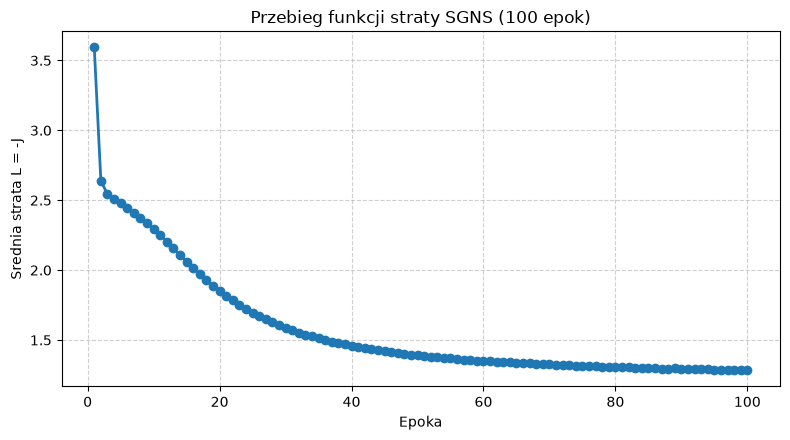

In [41]:
plt.figure(figsize=(8, 4.5))
plt.plot(range(1, len(loss_history) + 1), loss_history, marker="o", color="#1f77b4", linewidth=2)
plt.title(f"Przebieg funkcji straty SGNS ({len(loss_history)} epok)")
plt.xlabel("Epoka")
plt.ylabel("Srednia strata L = -J")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

### 4.1 Komentarz do zbieżności i dynamiki straty

- **Początkowa faza uczenia**: W pierwszych epokach strata gwałtownie spada (z 3.59 na 2.48), co odzwierciedla szybkie dopasowanie wektorów do statystyk współwystępowania.
- **Zachowanie pod koniec treningu**: Przy kontynuacji do 100 epok tempo spadku systematycznie maleje, a krzywa ulega wypłaszczeniu (strata osiąga ok. 1.28). Pod koniec cyklu (epoki 80-100) strata nie maleje już wyraźnie (zmiany poniżej 0.002 na epokę), co wskazuje na osiągnięcie zbieżności.

# Część 5: Analiza najbliższych sąsiadów przed uczeniem

In [42]:
def find_nearest_neighbors(word, embeddings_tensor, vocabulary, id_to_token, top_k=5):
    if word not in vocabulary:
        return []
    word_id = vocabulary[word]
    
    norm_embeddings = F.normalize(embeddings_tensor, p=2, dim=1)
    target_vec = norm_embeddings[word_id]
    
    cos_similarities = torch.mv(norm_embeddings, target_vec).clone()
    cos_similarities[word_id] = -float("inf")
    if UNK_TOKEN in vocabulary:
        cos_similarities[vocabulary[UNK_TOKEN]] = -float("inf")
        
    top_values, top_indices = torch.topk(cos_similarities, top_k)
    results = []
    for val, idx in zip(top_values.tolist(), top_indices.tolist()):
        results.append((id_to_token[idx], val))
    return results

In [43]:
selected_words = [
    "film", "movie", "story", "good", "director",
    "funny", "bad", "performances", "boring", "masterpiece"
]

print("Najblizsi sasiedzi przed uczeniem (losowe wagi poczatkowe V_in):")
print("=" * 80)

for word in selected_words:
    count = word_counts.get(word, 0)
    neighbors = find_nearest_neighbors(word, initial_in_embeddings, vocabulary, id_to_token, top_k=5)
    neighbors_str = ", ".join([f"{n} ({sim:.4f})" for n, sim in neighbors])
    print(f"Slowo: {word:<12} [liczebnosc: {count:4d}] -> {neighbors_str}")

Najblizsi sasiedzi przed uczeniem (losowe wagi poczatkowe V_in):
Slowo: film         [liczebnosc: 1152] -> stadium (0.3783), smartly (0.3637), establishes (0.3383), cars (0.3376), revenge (0.3341)
Slowo: movie        [liczebnosc: 1069] -> rouses (0.3449), devastatingly (0.3444), zaidan's (0.3385), poetically (0.3365), territory (0.3263)
Slowo: story        [liczebnosc:  373] -> section (0.3863), prima (0.3701), threat (0.3612), impressionable (0.3510), ensnare (0.3509)
Slowo: good         [liczebnosc:  329] -> uncle (0.3957), physics (0.3643), schiffer (0.3610), wretchedly (0.3528), engulfing (0.3504)
Slowo: director     [liczebnosc:  237] -> slipper (0.3951), visitor (0.3618), wear (0.3517), supple (0.3475), closed (0.3345)
Slowo: funny        [liczebnosc:  234] -> covering (0.3939), co (0.3469), faked (0.3361), tv (0.3283), about (0.3270)
Slowo: bad          [liczebnosc:  204] -> kafka (0.3770), passe (0.3748), contains (0.3723), someday (0.3705), melville's (0.3590)
Slowo: performan

### 5.1 Komentarz: nietrafione sąsiedztwa i wpływ rzadkości słów

- **Nietrafione sąsiedztwa**: Przed uczeniem wagi tablicy $V_\text{in}$ są losowe więc znalezione sąsiedztwa są całkowicie nietrafione semantycznie.
- **Wpływ rzadkości słów**: Rzadkość decyduje dopiero podczas treningu: słowa częste otrzymują regularne aktualizacje gradientowe, budując stabilne otoczenie, podczas gdy słowa rzadkie uczestniczą w nielicznych krokach i pozostają podatniejsze na szum.

# Część 6: Wizualizacja wektorów przed i po treningu (PCA)

In [44]:
from sklearn.decomposition import PCA

word_ids = [vocabulary[word] for word in selected_words]

vectors_before = initial_in_embeddings[word_ids].detach().cpu().numpy()
vectors_after = model.in_embeddings.weight[word_ids].detach().cpu().numpy()

combined_vectors = np.vstack([vectors_before, vectors_after])

pca = PCA(n_components=2, random_state=seed)
pca.fit(combined_vectors)

coords_before = pca.transform(vectors_before)
coords_after = pca.transform(vectors_after)

var_ratio = pca.explained_variance_ratio_
print(f"Wyjasniona wariancja przez PC1: {var_ratio[0] * 100:.2f}%")
print(f"Wyjasniona wariancja przez PC2: {var_ratio[1] * 100:.2f}%")
print(f"Lacznie wyjasniona wariancja (2 skladowe): {var_ratio.sum() * 100:.2f}%")

Wyjasniona wariancja przez PC1: 17.66%
Wyjasniona wariancja przez PC2: 16.40%
Lacznie wyjasniona wariancja (2 skladowe): 34.06%


findfont: Failed to find font weight medium, now using 400.


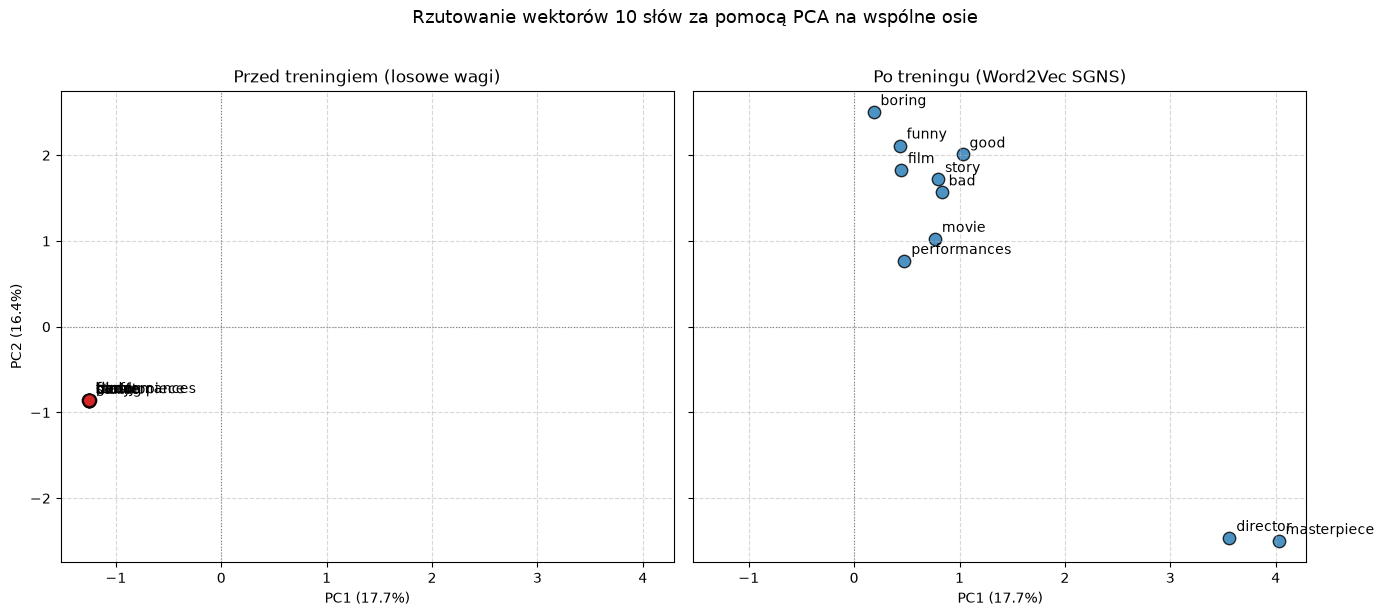

In [45]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)

ax1.scatter(coords_before[:, 0], coords_before[:, 1], color="#d62728", s=80, alpha=0.8, edgecolors="k")
for i, word in enumerate(selected_words):
    ax1.annotate(
        word,
        (coords_before[i, 0], coords_before[i, 1]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=10,
        fontweight="medium"
    )
ax1.set_title("Przed treningiem (losowe wagi)")
ax1.set_xlabel(f"PC1 ({var_ratio[0]*100:.1f}%)")
ax1.set_ylabel(f"PC2 ({var_ratio[1]*100:.1f}%)")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.axhline(0, color="grey", linewidth=0.8, linestyle=":")
ax1.axvline(0, color="grey", linewidth=0.8, linestyle=":")

ax2.scatter(coords_after[:, 0], coords_after[:, 1], color="#1f77b4", s=80, alpha=0.8, edgecolors="k")
for i, word in enumerate(selected_words):
    ax2.annotate(
        word,
        (coords_after[i, 0], coords_after[i, 1]),
        textcoords="offset points",
        xytext=(5, 5),
        fontsize=10,
        fontweight="medium"
    )
ax2.set_title("Po treningu (Word2Vec SGNS)")
ax2.set_xlabel(f"PC1 ({var_ratio[0]*100:.1f}%)")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.axhline(0, color="grey", linewidth=0.8, linestyle=":")
ax2.axvline(0, color="grey", linewidth=0.8, linestyle=":")

plt.suptitle("Rzutowanie wektorów 10 słów za pomocą PCA na wspólne osie", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

### 6.1 Komentarz do wizualizacji PCA i zniekształceń rzutowania

- **Porównanie rozkładu punktów**: Przed treningiem punkty są skupione w małym zakresie wokół zera (efekt losowej inicjalizacji). Po treningu uzyskują większą rozpiętość przestrzenną.
- **Zniekształcenia płaskiej projekcji**: Rzutowanie 100-wymiarowych wektorów na 2 wymiary zachowuje tylko część wariancji. Punkty leżące blisko siebie na płaszczyźnie mogą w pełnej przestrzeni $d=100$ mieć zupełnie inne kierunki. Rzeczywiste podobieństwa należy zawsze weryfikować w pełnej przestrzeni (np. za pomocą cosinusa).

## Wykorzystanie AI

- **Narzędzie**: Antigravity
- **Model**: Gemini 3.8 Flash (High)
- **Zakres wkładu**:
  - Część 1: Pobranie zbioru Rotten Tomatoes, implementacja normalizacji i tokenizacji tekstu, budowa słownika oraz generatora par Skip-gram dla okna o promieniu 2 z obsługą brzegów tekstu i bez przenoszenia okna między recenzjami.
  - Część 2: Konfiguracja powtarzalnego ziarna losowości (seed=42) i hiperparametrów (num_epochs = 100), wyznaczenie rozkładu szumu $f(w)^{3/4}$ na zbiorze treningowym, implementacja rekurencyjnego losowania negatywów z eliminacją kolizji ze słowem kontekstu oraz definicja modułu PyTorch z dwiema tablicami embeddingów $V_\text{in}$ i $U_\text{out}$ wraz z zachowaniem wag początkowych.
  - Część 3: Implementacja numerycznie stabilnej funkcji straty SGNS $L = -J$ z użyciem `torch.nn.functional.logsigmoid` oraz weryfikacja obliczeń iloczynów skalarnych, celu $J$ i straty na małym przykładzie wraz z komentarzem.
  - Część 4: Przygotowanie pętli treningowej Skip-gram z negative samplingiem i optymalizatorem Adam, przeprowadzenie treningu z rejestracją straty, wygenerowanie wykresu zbieżności oraz analiza tempa spadku straty pod koniec procesu uczenia.
  - Część 5: Dobór 10 słów testowych o zróżnicowanej częstości, implementacja wyszukiwania najbliższych sąsiadów na podstawie podobieństwa cosinusowego z wykluczeniem samego siebie, wyznaczenie sąsiedztw przed uczeniem oraz analiza nietrafionych sąsiedztw i wpływu rzadkości słów.
  - Część 6: Redukcja wymiarowości embeddingów za pomocą PCA dopasowanego wspólnie do połączonych wektorów sprzed i po treningu, wizualizacja ułożenia 10 słów na wspólnych osiach oraz analiza zniekształceń płaskiego rzutowania.
  - Czyszczenie kodu i dokumentacja: Usunięcie zbędnych komentarzy z komórek kodu oraz zintegrowanie pełnego rejestru promptów, kopii użytego skilla i wytycznych AGENTS.md bezpośrednio w notebooku.

### Wykorzystane prompty

```text
tool: Antigravity
model: Gemini 3.8 Flash (High)
/zajecia-nlp https://christop.faculty.wmi.amu.edu.pl/index.php?page=chapter&id=uczenie-glebokie-w-przetwarzaniu-tekstu&topic=osadzenia-i-reprezentacje in @[2/2.ipynb]
```

```text
tool: Antigravity
model: Gemini 3.8 Flash (High)
skopiuj pobieranie tekstow w takiej samej formie jak w @[1/1.ipynb] , przygotuj tekst i tokenizacje, wyznacz pary w promieniu 2, poprzez slowo kontekstu skip-gram
```

```text
tool: Antigravity
model: Gemini 3.8 Flash (High)
stworz dwa embeddingi wejsciowy i kontekstowy, gdy wylosujesz negatyw jako pozytyw wylosuj jeszcze raz rekurencyjnie. Pamietaj o wyprintowaniu seeda
```

```text
tool: Antigravity
model: Gemini 3.8 Flash (High)
sprawdz teraz na jednym malym przykladzie wynik oraz strate, nie licz recznie logarytmu tylko uzyj log-sigmoid
```

```text
tool: Antigravity
model: Gemini 3.8 Flash (High)
wytrenuj model na 100 epokach (podmien w poprzedniej definicji)
```

```text
tool: Antigravity
model: Gemini 3.8 Flash (High)
you can work on 5 epochs and just replace the value with 100 epochs and ill train it myself
```

```text
tool: Antigravity
model: Gemini 3.8 Flash (High)
continue
```

```text
tool: Antigravity
model: Gemini 3.8 Flash (High)
wybierz 10 slow i stworz porownanie cosinusowane najblizszych sasiadow przed uczeniem. przy porownywaniu nie porownuj wybranego slowa z samym soba, daj komentarz do rzadkosci slow oraz nietrafionych sasiedztw
```

```text
tool: Antigravity
model: Gemini 3.8 Flash (High)
zaprezentuj wykresy przed i po treningu jesli maja > 2 wymairy uzyj PCA
```

```text
tool: Antigravity
model: Gemini 3.8 Flash (High)
Clean up the file. Remove unecessary comments, leave them only to the sections it was specifically asked to add them to. You can add some simple instruction to AGENTS.md to avoid that in the future.
```

```text
tool: Antigravity
model: Gemini 3.8 Flash (High)
Dodaj w sekcji AI podsekcje z wykorzystanymi promptami, oraz aktualna kopie uzytych skilli oraz AGENTS.md tak, aby zawrzeć wszystko w 1 pliku
```

### Użyty skill (zajecia-nlp)

```markdown
---
name: zajecia-nlp
description: >
  Implements weekly Jupyter tasks for Uczenie głębokie w przetwarzaniu tekstu
  (Christop, AMU) from the live course page, and keeps submissions valid:
  saved notebook outputs, a full prompt log, a Wykorzystanie AI section, and
  ASCII hyphens with straight quotes. Use when editing a course notebook,
  used_prompts.md, a chapter task, tokenization, BoW, BPE, or a submission
  in this repo.
---

# Zajęcia NLP

Task text and dates live on the course page. Fetch them; do not rely on a copied chapter.

https://christop.faculty.wmi.amu.edu.pl/index.php?page=course&id=uczenie-glebokie-w-przetwarzaniu-tekstu

Chapter: `index.php?page=chapter&id=uczenie-glebokie-w-przetwarzaniu-tekstu&topic=<slug>`.

Organizational rules: the same URL with `topic=informacje-organizacyjne`.

Folder `N/` is week N. `N/N.ipynb` is the solution. `N/used_prompts.md` is the prompt log.

## Start

1. Fetch the chapter for this week. Read its **Zadanie** section. Fetch the organizational chapter when a deadline or submission rule is in play.
2. Read `N/N.ipynb` and `N/used_prompts.md`.
3. Restate the requested slice in one short paragraph: inputs, outputs, and the notebook heading it belongs under. Write code after that restatement follows the student's own request. When the message is only a paste of the chapter task, ask them to say what they want done before writing code.

## Implement

4. Change only the requested part. Keep every part of the week's task in the same notebook when the chapter says so.
5. Leave runnable code, saved outputs, and a short comment beside each plot or example the chapter asks to show.
6. Use markdown headings so each part of the task is easy to find.
7. Record the seed when the task asks for an experiment.
8. Fit vocabularies, tokenizers, and model selection on the training and validation splits. Score the chosen checkpoint once on the test split.

## Before you finish

9. Append this turn's user prompt to `N/used_prompts.md`, in send order, including follow-ups. Keep every earlier prompt. Record the tool and model name when they are known.
10. Add or update a notebook section **Wykorzystanie AI**: tool, model name when known, what it did, and a pointer to `used_prompts.md`.
11. In descriptions, conclusions, comments, and README, use the ASCII hyphen `-` and straight quotes `"`. Leave mathematical symbols, characters that belong to the data, and the prompt log as written.
12. Run `python3 .cursor/skills/zajecia-nlp/scripts/check_notebook.py N/N.ipynb`. Fix every reported hit in solution prose, then run it again.
13. Done when the notebook runs from the top, outputs for the requested part are saved, the prompt log includes this turn, **Wykorzystanie AI** points at that log, and the check script exits 0.

## Hand-in

A class task is one `.ipynb` with code, outputs, and the written analysis the chapter asks for.
```

### plik AGENTS.md (po edycji z przedostatniego promptu)

```markdown
# Agent Guidelines

- Do not add redundant or obvious comments inside code cells (e.g. avoid comments like `# Load dataset`, `# Initialize optimizer`, `# Plot chart`). Code should be clean and self-explanatory.
- Write explanatory comments or markdown prose only in the specific sections, plots, or examples where the assignment instructions explicitly ask for an explanation, analysis, or comment.
- Keep comments and analytical text concise and directly focused on answering the course requirements.
- In descriptions, conclusions, comments, and README, always use the ASCII hyphen `-` and straight quotes `"`.
```